# DSA 2050A — Week 9 practical GROUP lab
## Model selection and defensible evaluation 

**Work in your existing course groups.** Build one collaborative project and submit one shared GitHub repository link per group. List all member names, IDs and contributions in `README.md`.

**Case:** A fictional Kenyan internet provider wants to identify customers at risk of churn.
**Your group’s task:** Compare models fairly, investigate failures, document your decision, and evaluate the final test only after freezing the choice.

**Important:** Data is **synthetic for teaching**. `cancellation_confirmed` is known only *after* the outcome and is a deliberate leakage trap. Do not model using it.

**Before starting:** Open the `DSA2050_Week9_GitHub_Lab` folder in VS Code, select your Python environment, then run cells **from top to bottom**. Install packages using `python -m pip install -r requirements.txt` from the VS Code Terminal.

### Step 1 — Confirm environment and locate the datasets
**Click path:** VS Code → File → Open Folder → project folder → `notebooks/Week9_Model_Selection_Lab.ipynb` → **Select Kernel** (top right) → Python environment → **Run** each cell.

**Group discussion:** Why must the final test not be consulted before choosing a model? Add your explanation below.

**Response:** The final test set is our one unbiased estimate of how the model will behave on customers it has never seen. If we look at it while choosing a model, tuning, or changing the metric, information from the test labels leaks into our decisions. We would then be picking whichever model happens to score best on that particular sample, and the reported score would be optimistically biased because it was part of the selection process. So all comparison, tuning and diagnostics use the development data only with cross-validation, the choice is written to `reports/frozen_selection.json`, and the test CSV is read exactly once, afterwards. The notebook also refuses to recompute `final_metrics.json` if it already exists, which prevents repeated peeking.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance
import sklearn

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA = ROOT / 'data'
REPORTS = ROOT / 'reports'
REPORTS.mkdir(parents=True, exist_ok=True)
assert (DATA / 'churn_development.csv').exists(), 'Open the project folder in VS Code.'
print('Project:', ROOT.resolve())
print('Python:', sys.version.split()[0], 'scikit-learn:', sklearn.__version__)

Project: C:\Fall Semester 2026\Data Science Methodology\DSA Projects\Week 9 Lab\DSA2050_Week9_GitHub_Lab
Python: 3.12.6 scikit-learn: 1.5.2


### Step 2 — Open **development data only**, inspect, and remove leakage
Do **not** read `churn_final_test.csv` yet. Your prediction-time features must be available *before cancellation*.

In [2]:
dev = pd.read_csv(DATA / 'churn_development.csv')
print('Shape:', dev.shape)
print('Churn rate:', round(dev['churn'].mean(), 3))
print('Missing values:\n', dev.isna().sum())
display(dev.head())

TARGET = 'churn'
LEAKAGE_OR_IDS = ['churn', 'customer_id', 'cancellation_confirmed']
X_dev = dev.drop(columns=LEAKAGE_OR_IDS)
y_dev = dev[TARGET].astype(int)
print('Allowed features:', X_dev.columns.tolist())
assert 'cancellation_confirmed' not in X_dev.columns
assert 'customer_id' not in X_dev.columns

Shape: (2720, 11)
Churn rate: 0.335
Missing values:
 customer_id                 0
tenure_months               0
monthly_charges_kes       156
support_tickets_90d       120
service_calls_90d           0
plan_type                   0
region                     93
autopay                     0
customer_segment            0
cancellation_confirmed      0
churn                       0
dtype: int64


,customer_id,tenure_months,monthly_charges_kes,support_tickets_90d,service_calls_90d,plan_type,region,autopay,customer_segment,cancellation_confirmed,churn
0,CUST-12486,22,1943.94,1.0,2,Basic,Mombasa,Yes,Established,Active,0
1,CUST-12546,40,5003.13,1.0,0,Premium,Nairobi,No,Established,Active,0
2,CUST-11112,57,2796.23,1.0,1,Basic,Nairobi,Yes,Established,Active,0
3,CUST-12753,33,4697.39,NaN,0,Premium,Nairobi,Yes,Established,Active,0
4,CUST-10753,53,4330.27,2.0,1,Standard,Mombasa,No,Established,Active,0


Allowed features: ['tenure_months', 'monthly_charges_kes', 'support_tickets_90d', 'service_calls_90d', 'plan_type', 'region', 'autopay', 'customer_segment']


**Questions:** Identify (a) the target, (b) the unit of analysis, (c) the leakage column, and (d) why customer ID should not be used as a predictor.

**Group response:**

**(a) Target:** `churn` (1 = the customer left, 0 = stayed). We predict it as a binary classification problem.

**(b) Unit of analysis:** one row = one customer (one fictional internet subscriber). Features describe that customer's tenure, charges, support activity, plan, region, autopay and segment.

**(c) Leakage column:** `cancellation_confirmed`. It is only recorded after the customer has left, so it essentially restates the outcome. A model using it would look near-perfect in the lab and be useless in production, because at prediction time the cancellation has not happened yet.

**(d) Why `customer_id` is not a predictor:** it is an arbitrary label with no causal or behavioural meaning. A flexible model could memorise IDs and treat them as noise-fitting shortcuts, and a new customer's ID would carry no usable information, so it cannot generalise. The same applies to any ID-like ordering that might accidentally correlate with the outcome in this sample.

### Step 3 — Create leakage-safe preprocessing pipelines
**Analogy:** In each practice exam (CV fold), students should learn imputation values and scaling from the *practice questions* alone—not from the hidden answer sheet. The `Pipeline` re-fits preprocessing within each fold.

In [3]:
num_cols = X_dev.select_dtypes(include='number').columns.tolist()
cat_cols = X_dev.select_dtypes(exclude='number').columns.tolist()

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
category_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', category_pipe, cat_cols)
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Numeric:', num_cols)
print('Categorical:', cat_cols)
print('Same fixed CV:', cv)

Numeric: ['tenure_months', 'monthly_charges_kes', 'support_tickets_90d', 'service_calls_90d']
Categorical: ['plan_type', 'region', 'autopay', 'customer_segment']
Same fixed CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


### Step 4 — Establish a naive baseline
A **DummyClassifier** predicts based on a simple rule. It tells you what success without a real model looks like.

**Predict first:** Will a majority-class model have high accuracy if most customers stay, even when it never catches churn?

**Response:** Yes. The development churn rate is about 33.5%, so a model that always says "stays" gets roughly 66.5% accuracy while catching zero churners (recall 0, F1 0). The baseline results below confirm F1 = 0.0 on every fold. This is why accuracy is a poor metric for this imbalanced problem, and why any real model must beat an F1 of 0.

In [4]:
dummy_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent'))
])
metrics = {'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}
baseline_scores = cross_validate(dummy_pipe, X_dev, y_dev, cv=cv, scoring=metrics)
print('Baseline fold F1:', np.round(baseline_scores['test_f1'], 3))
print('Baseline mean F1:', round(baseline_scores['test_f1'].mean(), 3))

Baseline fold F1: [0. 0. 0. 0. 0.]
Baseline mean F1: 0.0


c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} i

### Step 5 — Compare two candidates using identical CV folds
Logistic regression is usually stable and interpretable. A decision tree learns if/then rules but can overfit. For each, search **three understandable settings**, not hundreds.

**Primary selection metric: F1** (balances precision and recall). Report precision and recall as secondary metrics.

**Do not switch the primary metric after seeing the winner.**

In [5]:
candidates = {
    'Logistic regression': (
        LogisticRegression(max_iter=2000, random_state=42),
        {'model__C': [0.1, 1, 10]}
    ),
    'Decision tree': (
        DecisionTreeClassifier(random_state=42),
        {'model__max_depth': [3, 5, 8]}
    )
}
searches = {}
logs = []
for name, (model, grid) in candidates.items():
    pipeline = Pipeline([('prep', preprocessor), ('model', model)])
    search = GridSearchCV(
        pipeline, grid, cv=cv, scoring=metrics,
        refit='f1', n_jobs=1, return_train_score=True
    )
    search.fit(X_dev, y_dev)
    searches[name] = search
    results = pd.DataFrame(search.cv_results_)
    for _, r in results.iterrows():
        row = {
            'model': name, 'settings': str(r['params']),
            'mean_f1': float(r['mean_test_f1']),
            'std_f1': float(r['std_test_f1']),
            'mean_precision': float(r['mean_test_precision']),
            'mean_recall': float(r['mean_test_recall'])
        }
        for i in range(5):
            row[f'fold_{i+1}_f1'] = float(r[f'split{i}_test_f1'])
        logs.append(row)

experiment_log = pd.DataFrame(logs).sort_values('mean_f1', ascending=False)
experiment_log.to_csv(REPORTS / 'experiment_log.csv', index=False)
display(experiment_log.round(3))
print('Saved:', REPORTS / 'experiment_log.csv')

,model,settings,mean_f1,std_f1,mean_precision,mean_recall,fold_1_f1,fold_2_f1,fold_3_f1,fold_4_f1,fold_5_f1
1,Logistic regression,{'model__C': 1},0.470,0.053,0.624,0.378,0.391,0.534,0.472,0.434,0.519
2,Logistic regression,{'model__C': 10},0.470,0.053,0.624,0.378,0.391,0.534,0.472,0.434,0.519
0,Logistic regression,{'model__C': 0.1},0.465,0.054,0.625,0.371,0.388,0.533,0.454,0.432,0.519
3,Decision tree,{'model__max_depth': 3},0.398,0.049,0.566,0.318,0.392,0.457,0.316,0.437,0.391
4,Decision tree,{'model__max_depth': 5},0.382,0.023,0.583,0.287,0.376,0.383,0.365,0.362,0.426
5,Decision tree,{'model__max_depth': 8},0.372,0.051,0.495,0.300,0.298,0.439,0.338,0.370,0.417


Saved: c:\Fall Semester 2026\Data Science Methodology\DSA Projects\Week 9 Lab\DSA2050_Week9_GitHub_Lab\reports\experiment_log.csv


### Step 6 — Examine score variation and select a candidate
Two models may have similar mean F1 but different fold stability. Larger `std_f1` means the validation score changed more across folds.

**Group task:** Compare the best logistic regression and best tree, then choose one. You **may** override the automatic highest-F1 default if you provide a defensible reason. Preserve the selected model's tuned hyperparameters.

**Response:**

 Logistic regression (best setting C = 1) has the higher mean F1, 0.470 (SD 0.053), versus 0.398 (SD 0.049) for the best decision tree (max_depth = 3). The fold-to-fold spread is similar (about 0.05), so the logistic regression's advantage of roughly 0.07 F1 is larger than the typical fold noise and it won on most individual folds. It also has higher recall and higher precision than the tree. We therefore kept the automatic highest-F1 choice and did not override it. C = 1 and C = 10 tie on F1 (0.470), so we keep the simpler, more regularised C = 1 that the grid search ranks first.

**Decision question (is a 0.005 mean-F1 gain convincing if the alternative is more variable?):**

 No. 0.005 is about ten times smaller than the fold SD (about 0.05), so it is within noise, and we would prefer the more stable and simpler model. Here the gap is about 0.07 with similar variability, so it is convincing.

**Five-fold F1 scores of the best configurations:** 

Logistic regression (C = 1): 0.391, 0.534, 0.472, 0.434, 0.519. Decision tree (max_depth = 3): 0.392, 0.457, 0.316, 0.437, 0.391.

### Additional Model Evaluation: Precision and Recall

To provide a broader comparison of the two models, mean precision and recall are also examined.

Mean F1 Score(Logistic Regression = 0.470, Decision tree = 0.398)
Mean Precision(Logistic Regression = 0.624, Decision tree = 0.566)
Mean Recall(Logistic Regression = 0.378, Decision tree = 0.318)
F1 Standard Deviation(Logistic Regression = 0.053, Decision tree = 0.049)



### Interpretation:

Logistic Regression achieved higher mean precision (0.624) and recall (0.378) than the Decision Tree, which achieved 0.566 and 0.318 respectively.

The higher precision indicates that Logistic Regression makes fewer incorrect positive churn predictions relative to its positive predictions. Its higher recall also indicates that it identifies a larger proportion of actual churners.

Since identifying customers who are likely to churn is important, the higher recall makes Logistic Regression the preferable candidate among the two models evaluated.

In [6]:
best_by_model = (experiment_log.sort_values('mean_f1', ascending=False)
                 .drop_duplicates(subset='model').reset_index(drop=True))
display(best_by_model[['model','mean_f1','std_f1','mean_recall','mean_precision']].round(3))

# Change only if your explanation supports the different choice.
CHOSEN_MODEL = best_by_model.iloc[0]['model']
assert CHOSEN_MODEL in searches
chosen_search = searches[CHOSEN_MODEL]
chosen_pipeline = chosen_search.best_estimator_
print('Chosen:', CHOSEN_MODEL)
print('Settings:', chosen_search.best_params_)
print('Development CV F1:', round(chosen_search.best_score_, 3))

,model,mean_f1,std_f1,mean_recall,mean_precision
0,Logistic regression,0.470,0.053,0.378,0.624
1,Decision tree,0.398,0.049,0.318,0.566


Chosen: Logistic regression
Settings: {'model__C': 1}
Development CV F1: 0.47


### Step 7 — Out-of-fold errors and subgroup analysis

`cross_val_predict` makes each development-row prediction from a model trained on **other folds**. Use these to inspect false positives (flagged churn that did not happen) and false negatives (missed churn).

**Caution:** Out-of-fold diagnostics use the same development dataset involved in selection; do not call them an untouched final-test estimate.

**Response:** 

With the chosen logistic regression the out-of-fold confusion matrix has 566 false negatives (churners we missed) and 205 false positives (loyal customers we flagged), out of 2,720 customers. Overall recall for churn is only 0.38 and precision is 0.63, so we miss about 62% of churners.

              precision    recall  f1-score   support

           0       0.74      0.89      0.81      1810
           1       0.63      0.38      0.47       910

    accuracy                           0.72      2720
   macro avg       0.68      0.63      0.64      2720
weighted avg       0.70      0.72      0.69      2720



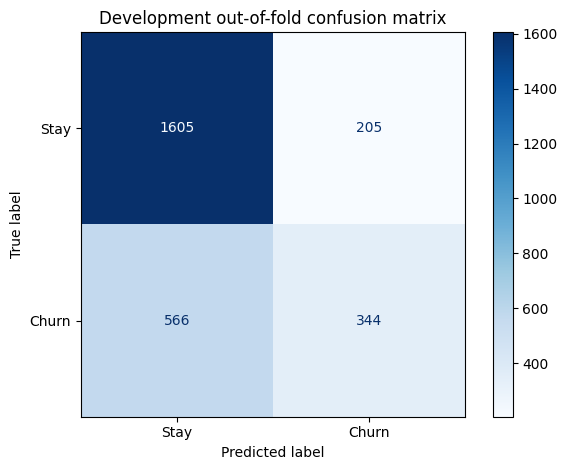

error_type
Correct           1949
False negative     566
False positive     205
Name: count, dtype: int64


,customer_id,customer_segment,plan_type,churn,prediction,error_type
5,CUST-12096,Established,Standard,1,0,False negative
10,CUST-11528,Established,Basic,1,0,False negative
12,CUST-12416,New,Basic,0,1,False positive
13,CUST-12232,Established,Basic,0,1,False positive
18,CUST-12749,Established,Standard,1,0,False negative
19,CUST-10694,Established,Basic,0,1,False positive
24,CUST-12737,Established,Basic,1,0,False negative
26,CUST-12112,Established,Basic,1,0,False negative


In [7]:
oof_pred = cross_val_predict(chosen_pipeline, X_dev, y_dev, cv=cv, method='predict')
print(classification_report(y_dev, oof_pred, zero_division=0))
cm = confusion_matrix(y_dev, oof_pred, labels=[0,1])
ConfusionMatrixDisplay(cm, display_labels=['Stay','Churn']).plot(cmap='Blues')
plt.title('Development out-of-fold confusion matrix')
plt.tight_layout()
plt.savefig(REPORTS / 'development_confusion_matrix.png', dpi=150)
plt.show()

errors = dev[['customer_id','customer_segment','plan_type','churn']].copy()
errors['prediction'] = oof_pred
errors['error_type'] = np.select([
    (errors.churn==1)&(errors.prediction==0),
    (errors.churn==0)&(errors.prediction==1)],
    ['False negative','False positive'],default='Correct')
print(errors.error_type.value_counts())
display(errors.query("error_type != 'Correct'").head(8))

**Subgroup task:** Is recall worse for new customers than established customers? Report subgroup sample size, number of actual churners, recall, and interpret cautiously.

**Response:**

 The assumption in the question is not supported because the pattern is actually reversed. Using out-of-fold predictions on the development data:

| Segment | Customers | Actual churners | Recall | Precision | False negatives |
|---|---|---|---|---|---|
| Established | 2,268 | 649 | 0.216 | 0.593 | 509 |
| New | 452 | 261 | 0.782 | 0.652 | 57 |

The model catches about 78% of churning new customers but only about 22% of churning established customers. Both groups have reasonable sample sizes (649 and 261 actual churners), so this is not a small sample bias, although the new group is much smaller. A plausible explanation is that the model has learned "short tenure means churn", which works for new customers, while established customers who leave do so for reasons that the available features do not capture well. Because established customers make up most of the base, 509 of the 566 missed churners come from them. This is an association in the data, not a proven reason.

In [8]:
group_rows = []
for group, part in errors.groupby('customer_segment'):
    true = part['churn'].to_numpy()
    pred = part['prediction'].to_numpy()
    group_rows.append({
        'segment': group, 'n_customers': len(part),
        'n_actual_churn': int(true.sum()),
        'recall': recall_score(true,pred,zero_division=0),
        'precision': precision_score(true,pred,zero_division=0),
        'false_negatives': int(((true==1)&(pred==0)).sum())
    })
subgroup = pd.DataFrame(group_rows)
subgroup.to_csv(REPORTS/'subgroup_metrics.csv',index=False)
display(subgroup.round(3))

,segment,n_customers,n_actual_churn,recall,precision,false_negatives
0,Established,2268,649,0.216,0.593,509
1,New,452,261,0.782,0.652,57


### Step 8 — Permutation importance on development validation data
Hold out a **small validation slice from the development data** for the importance demo, fit on the remaining development rows, and ask how F1 changes when one feature is shuffled. **Importance does not prove causality.**

,feature,importance_mean,importance_std
0,tenure_months,0.079,0.024
2,support_tickets_90d,0.035,0.016
7,customer_segment,0.018,0.006
1,monthly_charges_kes,0.016,0.023
4,plan_type,0.015,0.015
5,region,0.006,0.013
3,service_calls_90d,0.003,0.007
6,autopay,0.002,0.017


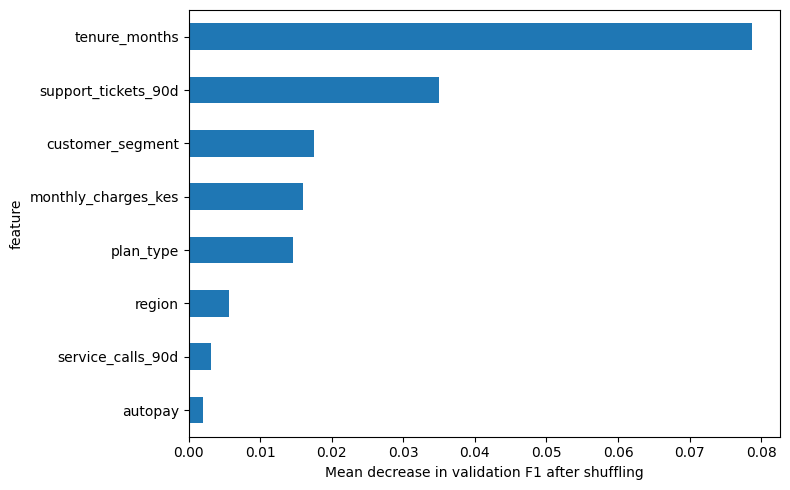

In [ ]:
X_inner, X_validation, y_inner, y_validation = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=2050, stratify=y_dev
)
interpret_model = chosen_pipeline
interpret_model.fit(X_inner,y_inner)
importance = permutation_importance(
    interpret_model,X_validation,y_validation,
    scoring='f1', n_repeats=5,random_state=42,n_jobs=1
)
importance_table = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean':importance.importances_mean,
    'importance_std':importance.importances_std
}).sort_values('importance_mean',ascending=False)
importance_table.to_csv(REPORTS/'permutation_importance.csv',index=False)
display(importance_table.round(3))
ax = importance_table.sort_values('importance_mean').plot.barh(
    x='feature',y='importance_mean',legend=False,figsize=(8,5))
ax.set_xlabel('Mean decrease in validation F1 after shuffling')
plt.tight_layout()
plt.savefig(REPORTS/'permutation_importance.png',dpi=150)
plt.show()

**Questions:** Name the two most relied-upon features and two limitations of permutation importance (examples: correlated features, small sample, not causal).

**Response:** 

The two most relied-upon features are **`tenure_months`** with mean F1 drop about 0.079 and **`support_tickets_90d`** with mean drop about 0.035. `customer_segment` (about 0.018) is third and is closely related to tenure.

Limitations of permutation importance:
- **Correlated features share credit.** Tenure and customer segment carry overlapping information, so shuffling one can understate its importance because the other still supplies the signal.
- **Small validation sample and noisy estimates.** The importance comes from a 25% validation slice and 5 repeats. Several standard deviations are as large as their means for example `monthly_charges_kes` and `autopay`, so the ranking of the lower features is unreliable.
- **It is not causal.** It only shows what the fitted model relies on to predict. Shortening tenure or reducing tickets would not necessarily change whether a customer churns, because other unobserved factors may drive both.

### Step 9 — Freeze your choice BEFORE the final test
Complete the **100+ character** rationale in the next cell. It should reference the metric, cross-validation mean and variation, error behaviour, subgroup results, and complexity. The code saves a written selection record before the final-test cell.

**Do not run the final step until the rationale is complete.**

In [10]:
RATIONALE = """We select Logistic regression (C = 1) because it has the highest mean 5-fold stratified CV F1, our pre-declared primary metric: 0.470 (SD 0.053) versus 0.398 (SD 0.049) for the best decision tree (max_depth = 3), and it also has better recall (0.378 vs 0.318) and precision (0.624 vs 0.566). The fold spread is similar for both, so the gap is not explained by noise, and it won on most folds. It is also the simpler, more interpretable model, and its regularisation (C = 1 over C = 10, which tied) limits overfitting. Out-of-fold error analysis shows 566 false negatives and 205 false positives; recall is a weak 0.38 overall, and it is much lower for Established customers (0.22, 649 churners) than New customers (0.78, 261 churners). We accept this weakness for now and will report it clearly, but we do not tune the model using the final test. The absolute F1 is modest, but it is far above the dummy baseline F1 of 0."""
assert not RATIONALE.startswith('REPLACE THIS TEXT'), 'Write your own rationale first.'
assert len(RATIONALE.strip()) >= 100, 'Write at least 100 characters.'
freeze = {
    'selected_model': CHOSEN_MODEL,
    'best_params': chosen_search.best_params_,
    'primary_metric': 'f1',
    'cv_mean_f1': float(chosen_search.best_score_),
    'rationale': RATIONALE.strip(),
    'random_seed': 42,
    'scikit_learn_version': sklearn.__version__
}
(REPORTS/'frozen_selection.json').write_text(json.dumps(freeze,indent=2),encoding='utf-8')
print('Selection frozen in reports/frozen_selection.json')

Selection frozen in reports/frozen_selection.json


### Step 10 — ONE final evaluation: only now read the test CSV
The code refuses to recalculate final performance if `reports/final_metrics.json` already exists. **Never change a selected model after observing its final result and then claim that the same test is unbiased.**

In [11]:
final_path = REPORTS/'final_metrics.json'
assert (REPORTS/'frozen_selection.json').exists(), 'Freeze selection before testing.'
if final_path.exists():
    print('Final test already evaluated. Reading the existing saved metrics (NOT rerunning).')
    print(final_path.read_text(encoding='utf-8'))
else:
    final_test = pd.read_csv(DATA/'churn_final_test.csv')  # first and only use
    X_test = final_test.drop(columns=LEAKAGE_OR_IDS)
    y_test = final_test[TARGET].astype(int)
    final_model = chosen_search.best_estimator_
    final_model.fit(X_dev,y_dev)  # refit on entire development dataset
    final_pred = final_model.predict(X_test)
    final_metrics = {
        'model':CHOSEN_MODEL,
        'n_test':int(len(y_test)),
        'cv_mean_f1':round(float(chosen_search.best_score_),4),
        'test_accuracy':round(float(accuracy_score(y_test,final_pred)),4),
        'test_f1':round(float(f1_score(y_test,final_pred,zero_division=0)),4),
        'test_precision':round(float(precision_score(y_test,final_pred,zero_division=0)),4),
        'test_recall':round(float(recall_score(y_test,final_pred,zero_division=0)),4),
        'confusion_matrix_0_1':confusion_matrix(y_test,final_pred,labels=[0,1]).tolist()
    }
    final_path.write_text(json.dumps(final_metrics,indent=2),encoding='utf-8')
    print(json.dumps(final_metrics,indent=2))
print('Done. Complete README and submit your GitHub repository link.')

Final test already evaluated. Reading the existing saved metrics (NOT rerunning).
{
  "model": "Logistic regression",
  "n_test": 680,
  "cv_mean_f1": 0.4701,
  "test_accuracy": 0.7,
  "test_f1": 0.4486,
  "test_precision": 0.5845,
  "test_recall": 0.364,
  "confusion_matrix_0_1": [
    [
      393,
      59
    ],
    [
      145,
      83
    ]
  ]
}
Done. Complete README and submit your GitHub repository link.


### Final-test interpretation:

The frozen logistic regression (C = 1) was refit on all 2,720 development rows and scored once on 680 unseen customers: **F1 = 0.449, precision = 0.585, recall = 0.364, accuracy = 0.700**. The confusion matrix is 393 true stays, 59 false positives, 145 false negatives and 83 true churners. The mean CV F1 was 0.470, so the test F1 is about 0.021 lower. That gap is well under one fold standard deviation (0.053), so we do not consider it concerning but it is the small optimism we expect from selecting on the development data. We did not change the model after seeing these numbers.

## Group Reflection:

**1. Which model was selected and why was it defensible?**

Logistic regression with C = 1. Under the pre-declared primary metric (F1) and identical 5-fold stratified CV (shuffle, seed 42), it scored a mean F1 of 0.470 with a fold SD of 0.053, against 0.398 (SD 0.049) for the best decision tree. It also had better precision and recall, similar stability, and is simpler to explain. The choice was made on development data only and frozen before the test file was read.

**2. What did false negatives mean for this provider? Which subgroup struggled most?**

A false negative is a customer who left without being flagged, so the provider loses the chance to run a retention offer and loses the revenue. We had 566 of them in out-of-fold predictions on the development data (overall recall 0.38). **Established customers struggled most**: recall was 0.22 (509 missed of 649 churners) versus 0.78 for New customers (57 missed of 261). Because established customers are most of the customer base, a retention team using this model would miss most of the churn in that group.

**3. Which feature was highest in permutation importance, and why does that not imply causation?**

`tenure_months` (mean F1 drop about 0.079), followed by `support_tickets_90d` (about 0.035). Permutation importance only measures how much the fitted model depends on a feature for prediction. Tenure may be a proxy for other things (contract age, pricing at sign-up, life stage), correlated features share credit, and the estimate is noisy. Changing a customer's tenure or ticket count would not necessarily change their chance of leaving.

**4. Compare final-test F1 with mean CV F1. Did your model generalize reasonably?**

Test F1 was 0.449 against a CV mean of 0.470, a drop of about 0.02, well within one fold SD (0.053). The model generalised reasonably. Test precision (0.585) and recall (0.364) are also close to the CV values (0.624 and 0.378). The absolute performance is still modest, since the model misses roughly 64% of churners on the test set.

**5. State two limitations of this synthetic dataset and one step before deploying a real churn model.**

The data is synthetic and fictional, so relationships such as the strong tenure effect may be simpler or different from real customer behaviour therefore results cannot be assumed to transfer to a real provider.

It is a single snapshot with no time dimension, so we cannot check drift, seasonality or changes in pricing and competition. Important drivers of churn such as competitor offers, network quality, payment problems are not recorded.

Before real deployment we would run a temporal validation and a pilot with human review of flagged customers. We would monitor recall by subgroup, especially for established customers, and consider a lower decision threshold or a different model to improve recall.

---
**Lab reflection prompts**

*Why share folds?* 
So all models face identical splits and differences come from the models, not an easier split.

*What does F1 measure?* 
The harmonic mean of precision and recall; it is low if either is low.

*Where do errors concentrate?* 
In false negatives (566 vs 205 false positives), mostly Established customers (509 of 566).

*Highest-reliance feature?*
`tenure_months`.

*Why is the final-test score not a tuning tool?* 
Using it to adjust the model makes it part of selection, so it stops being an unbiased estimate and issues found are documented as limitations.